# 07b — Challenger Models

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



In [3]:
# Cell 3 — common imports and settings for this notebook
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
from scorelab import target, attributes as A, binning as B, scorecard as S, validation as V, fairness as F
from scorelab import challengers as C, reject_inference as R, monitoring as M, report as REP
from scorelab import tuning as T, explain as E, survival as SV, causal as CA
MODELS = config.MODELS_DIR; MODELS.mkdir(exist_ok=True)
SAMPLE_FRAC = None     # None = full data (recommended for the fitting notebooks); e.g. 0.10 for a quick pass
cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
def load_frame(splits=("train", "validate", "oot"), **kw):
    """Observable, non-excluded loans with attributes built; indeterminates dropped unless asked."""
    f = target.modeling_frame(con, splits=splits, sample_frac=SAMPLE_FRAC, **kw)
    return A.build_attributes(f)
MEANINGS = {a.name: a.meaning for a in A.REGISTRY}
DIRECTIONS = {a.name: a.direction for a in A.REGISTRY}

## What this notebook settles

Whether any model family beats the card out of time by enough to justify its explainability cost, once each one is tuned honestly. The challengers are fitted on the training vintages: XGBoost (tuned with Optuna and at the NB07 defaults), LightGBM, random forest, two EBMs (monotone with main effects only, and unconstrained with pairwise terms), two small MLPs (each tuned with Optuna) and a stacked ensemble. **Models are tuned and chosen on 2015. Tuning, early stopping, the stack's meta-model, the choice of challenger and the recalibration of the tuned GBM all use the 2015 validation year only. The 2016 out-of-time year is reported once, in the last table, after those choices are fixed.**

**Inputs are held fixed so model and input-set effects can be told apart.** Every tree model, the EBMs and the first MLP see the same NB03 candidate attributes (the trees handle missing values natively; the MLP gets them standardised, median-imputed, with a missing-indicator column per attribute that has missing values, all fitted on 2013–2014 only). The second MLP sees the NB04 WOE attributes, the card's own coding. The `inputs` column of the comparison table states each model's input set.

Decisions: **W — the model set and the search budget**, **X — which challenger goes forward** (to NB07c for explanation, and to the champion memo in NB07).

In [4]:
frame = load_frame()
tr, va, oot = (frame[frame.split == s] for s in ("train", "validate", "oot"))
card, specs = S.load_card(MODELS / "champion"); card_attrs = card.attributes
cands = json.loads((MODELS / "candidate_attributes.json").read_text(encoding="utf-8"))["candidates"]
print(f"train {len(tr):,} · validate {len(va):,} · oot {len(oot):,} · {len(cands)} candidates · card on {len(card_attrs)}")

p_card = {"va": S.score(va, card, specs)["p_bad"].to_numpy(), "oot": S.score(oot, card, specs)["p_bad"].to_numpy()}
bins = B.load_specs(MODELS / "bins.json")              # NB04 bins: the WOE inputs option for the MLP

train 364,774 · validate 413,791 · oot 419,611 · 27 candidates · card on 8


### Decision W — Model set and search budget

Which families earn a place in the comparison, and how much search each gets. A GBM trial on the full training set takes 20–60 s, an MLP trial a few minutes. Is the search budget enough (the spread of the top-5 validation AUCs below tells you whether the search has flattened)? Which models must keep monotone constraints for reason codes to be defensible? Read the two MLPs together: the raw-input MLP against the GBM isolates the model family on the same inputs; the WOE MLP against the raw MLP isolates the input set for the same family.

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**Keep the model set and the budgets. The searches have flattened.**

**XGBoost:** 23 of 30 trials, stopped by the 45-minute cap. The spread of the top-5 validation AUCs is 0.0002 (0.662844 to 0.662994), so more trials would not move the result.

**MLPs:** each ran 12 trials. The top-5 spreads are:
- raw inputs: 0.0008 (0.662493 to 0.663292);
- WOE inputs: 0.0007 (0.660166 to 0.660904).

**Monotone constraints stay on** for XGBoost, LightGBM, the random forest and one EBM: these are the models whose reason codes could be defended.

The EBM with 10 pairs and the MLPs are unconstrained. They are in the table to measure what monotonicity costs, not to be promoted.

**Reading the two MLPs (2015 AUC):**
- **Family on the same inputs:** the raw MLP (0.6633) is level with the tuned XGBoost (0.6630).
- **Input set for the same family:** the WOE MLP (0.6611) is 0.0022 below the raw MLP. Most of that is the input set: it sees 19 binned attributes against 27 raw candidates.

In [5]:
N_TRIALS_XGB, N_TRIALS_MLP = 23, 12      # Optuna budgets per search (validation AUC on 2015); each MLP gets its own
# The first full-data run allowed 30 XGBoost trials under a 45-minute cap and stopped at 23. A wall-clock stop is not
# reproducible (it depends on machine load), so the budget is pinned to the 23 trials that ran and the caps are off.
XGB_TIMEOUT, MLP_TIMEOUT = None, None
woe_attrs = [a for a in cands if a in bins]
MLP_RAW, MLP_WOE = f"MLP (raw, {len(cands)} candidates)", f"MLP (WOE, {len(woe_attrs)} binned)"
RAW = f"raw, {len(cands)} NB03 candidates"
INPUTS = {
    "Scorecard (champion)": f"WOE, {len(card_attrs)} card attributes",
    "XGBoost (tuned, monotone)": RAW + " (missing native)", "XGBoost (NB07 defaults)": RAW + " (missing native)",
    "LightGBM (monotone)": RAW + " (missing native)", "Random forest (monotone)": RAW + " (missing native)",
    "EBM (monotone, main effects)": RAW + " (missing native)", "EBM (10 pairs, unconstrained)": RAW + " (missing native)",
    MLP_RAW: RAW + ", standardised, median-imputed + missing flags (fit on 2013-14)",
    MLP_WOE: f"WOE, {len(woe_attrs)} NB04 binned attributes",
}
fits, times = {}, {}

In [6]:
# Gradient boosting: Optuna search on 2015, then the tuned model, the NB07 default and LightGBM
best_xgb, trials_xgb = T.tune_xgb(tr, va, cands, n_trials=N_TRIALS_XGB, timeout=XGB_TIMEOUT)
print(f"{len(trials_xgb)} XGBoost trials"); display(trials_xgb.head(10))
print("spread of the top-5 validation AUCs:", round(T.best_trial_gap(trials_xgb), 4))
xgb_params = {k: v for k, v in best_xgb.items() if k != "n_rounds"}
fits["XGBoost (tuned, monotone)"], times["XGBoost (tuned, monotone)"] = C.timed(
    C.fit_xgb, tr, tr["bad"], va, va["bad"], cands, monotone=True, params=xgb_params)
fits["XGBoost (NB07 defaults)"], times["XGBoost (NB07 defaults)"] = C.timed(
    C.fit_xgb, tr, tr["bad"], va, va["bad"], cands, monotone=True)
fits["LightGBM (monotone)"], times["LightGBM (monotone)"] = C.timed(
    C.fit_lgbm, tr, tr["bad"], va, va["bad"], cands, monotone=True)

23 XGBoost trials


,number,valid_auc,params_colsample_bytree,params_eta,params_gamma,params_lambda,params_max_depth,params_min_child_weight,params_subsample,user_attrs_best_iteration,user_attrs_valid_log_loss,duration_s
0,21,0.662994,0.837932,0.020678,0.779491,0.464382,6,205.170073,0.756245,620,0.340670,166.4
1,17,0.662932,0.872983,0.026625,1.084629,0.153597,5,154.419702,0.750900,594,0.340697,134.9
2,16,0.662882,0.788574,0.032552,2.297622,0.121634,5,128.200602,0.797286,483,0.340660,110.5
3,22,0.662869,0.871295,0.033782,0.337849,0.124777,6,92.370656,0.734059,373,0.340737,158.7
4,14,0.662844,0.722260,0.029384,1.718970,0.242371,5,64.926262,0.781476,531,0.340704,120.2
5,5,0.662831,0.664091,0.025044,2.475885,0.200587,6,40.665633,0.873693,529,0.340721,150.2
6,20,0.662812,0.816497,0.020546,2.130653,0.105148,5,58.066586,0.829957,527,0.340705,175.0
7,10,0.662714,0.559814,0.024021,3.764938,9.356880,6,15.560705,0.811386,531,0.340716,122.6
8,19,0.662710,0.964635,0.022334,0.994243,0.161539,5,50.070822,0.820110,525,0.340717,160.5
9,18,0.662646,0.757572,0.030290,1.804347,0.169031,5,377.101364,0.688444,461,0.340690,157.9


spread of the top-5 validation AUCs: 0.0002


In [7]:
# Random forest and the two EBMs
fits["Random forest (monotone)"], times["Random forest (monotone)"] = C.timed(
    C.fit_random_forest, tr, tr["bad"], cands, monotone=True)
fits["EBM (monotone, main effects)"], times["EBM (monotone, main effects)"] = C.timed(
    C.fit_ebm, tr, tr["bad"], cands, monotone=True)
fits["EBM (10 pairs, unconstrained)"], times["EBM (10 pairs, unconstrained)"] = C.timed(
    C.fit_ebm, tr, tr["bad"], cands, monotone=False, interactions=10)

MLP (raw, 27 candidates) (12 trials)


,number,valid_auc,params_alpha,params_batch_size,params_hidden,params_learning_rate,user_attrs_best_epoch,user_attrs_valid_log_loss,duration_s
0,8,0.663292,0.000176,512,16,0.003483,13,0.342380,32.9
1,11,0.663173,0.000048,1024,32-16,0.004484,16,0.341946,44.0
2,7,0.663168,0.000021,1024,64-32,0.000134,37,0.340859,199.3
3,6,0.662782,0.000006,256,64-32,0.000103,22,0.341500,109.8
4,10,0.662493,0.001028,512,16,0.003904,8,0.342227,15.7


MLP (WOE, 19 binned) (12 trials)


,number,valid_auc,params_alpha,params_batch_size,params_hidden,params_learning_rate,user_attrs_best_epoch,user_attrs_valid_log_loss,duration_s
0,11,0.660904,0.000035,1024,64-32,0.000141,40,0.341217,85.5
1,6,0.660808,0.000006,256,64-32,0.000103,29,0.341695,212.6
2,7,0.660784,0.000021,1024,64-32,0.000134,40,0.341250,108.3
3,3,0.660690,0.000546,2048,32,0.000759,40,0.341304,39.9
4,2,0.660166,0.000114,512,64-32,0.001530,6,0.341040,29.0


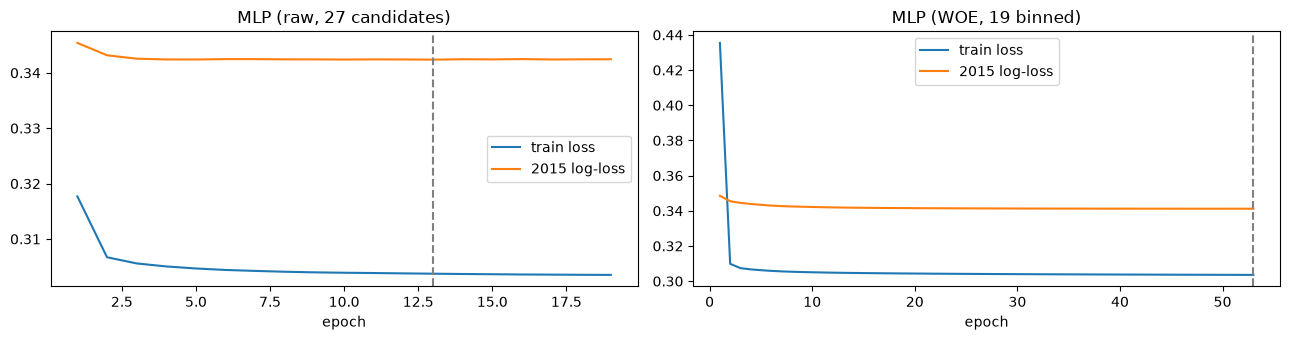

missing-indicator columns in the raw MLP: ['mths_since_recent_inq', 'mths_since_last_record', 'revol_util', 'bc_util', 'percent_bc_gt_75', 'bc_open_to_buy', 'avg_cur_bal', 'mo_sin_old_il_acct', 'revol_bal_to_limit', 'bal_ex_mort_to_limit']


In [8]:
# Two MLPs, same Optuna budget and early stopping on 2015: raw candidates vs WOE inputs
best_mlp = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for (name, attrs_m, specs_m), ax in zip(((MLP_RAW, cands, None), (MLP_WOE, woe_attrs, bins)), axes):
    best_mlp[name], trials_m = T.tune_mlp(tr, va, attrs_m, specs=specs_m, n_trials=N_TRIALS_MLP, timeout=MLP_TIMEOUT)
    print(name, f'({len(trials_m)} trials)'); display(trials_m.head(5))
    fits[name], times[name] = C.timed(C.fit_mlp, tr, tr["bad"], va, va["bad"], attrs_m, specs=specs_m, **best_mlp[name])
    h = fits[name].history
    ax.plot(h.epoch, h.train_loss, label="train loss"); ax.plot(h.epoch, h.valid_log_loss, label="2015 log-loss")
    ax.axvline(fits[name].best_epoch, ls="--", c="grey"); ax.set_xlabel("epoch"); ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()
print("missing-indicator columns in the raw MLP:", fits[MLP_RAW].scaler.flagged)

In [9]:
# Stacked ensemble: meta-model on 2015 predictions of models trained on 2013-2014
STACK_BASE = ["XGBoost (tuned, monotone)", "Random forest (monotone)", "EBM (monotone, main effects)", MLP_RAW]
INPUTS["Stacked ensemble"] = "log-odds of: " + ", ".join(STACK_BASE)
base_va = {n: C.predict_p(fits[n], va) for n in STACK_BASE}
stack, times["Stacked ensemble"] = C.timed(C.fit_stack, base_va, va["bad"])
display(pd.Series(stack.weights, name="weight on log-odds").round(3))

XGBoost (tuned, monotone)       0.646
Random forest (monotone)       -0.118
EBM (monotone, main effects)   -0.146
MLP (raw, 27 candidates)        0.549
Name: weight on log-odds, dtype: float64

In [10]:
# Selection on 2015 only. Tuning, early stopping and the stack's meta-model all used 2015, so these numbers flatter
# the tuned models and the stack; they rank the candidates, they are not results.
preds_va = {"Scorecard (champion)": p_card["va"]}
preds_va.update({n: C.predict_p(m, va) for n, m in fits.items()})
preds_va["Stacked ensemble"] = stack.predict(base_va)
cmp_va = V.model_comparison(va["bad"], preds_va, reference="Scorecard (champion)", fit_seconds={**times, "Scorecard (champion)": np.nan},
                            inputs=INPUTS).sort_values("gini", ascending=False).reset_index(drop=True)
cmp_va.to_csv(config.DOCS_DIR / "exhibits" / "challenger_comparison_2015.csv", index=False)
display(cmp_va.drop(columns=["explainability"]))
singles = cmp_va[~cmp_va.model.isin(["Scorecard (champion)", "Stacked ensemble"])]
BEST_ON_2015 = singles.model.iloc[0]
print("highest 2015 Gini among single challengers:", BEST_ON_2015)

# Recalibrate the tuned GBM on 2015 (logit-linear), so its probabilities are on the 2015 level before the pilot report
RECAL = V.fit_recalibration(va["bad"], preds_va["XGBoost (tuned, monotone)"])
print("recalibration of the tuned GBM on 2015:", {k: round(v, 4) if isinstance(v, float) else v for k, v in RECAL.items()})

,model,inputs,auc,gini,gini_ci_low,gini_ci_high,ks,brier,log_loss,calib_slope,calib_intercept,calib_in_the_large,gini_vs_ref,gini_vs_ref_ci_low,gini_vs_ref_ci_high,ci_excludes_zero,delong_p_vs_ref,fit_seconds
0,Stacked ensemble,"log-odds of: XGBoost (tuned, monotone), Random...",0.6660,0.3321,0.3271,0.3371,0.2419,0.0978,0.3383,0.9970,-0.0062,-0.0005,0.0304,0.0283,0.0325,True,0.0000,0.8856
1,"EBM (10 pairs, unconstrained)","raw, 27 NB03 candidates (missing native)",0.6655,0.3309,0.3259,0.3359,0.2410,0.0983,0.3404,1.0385,0.2877,0.2059,0.0292,0.0269,0.0316,True,0.0000,173.7986
2,"MLP (raw, 27 candidates)","raw, 27 NB03 candidates, standardised, median-...",0.6633,0.3266,0.3215,0.3316,0.2378,0.0986,0.3424,0.9721,0.2145,0.2756,0.0249,0.0225,0.0273,True,0.0000,18.9555
3,"XGBoost (tuned, monotone)","raw, 27 NB03 candidates (missing native)",0.6630,0.3260,0.3209,0.3310,0.2371,0.0983,0.3407,0.9730,0.1323,0.1892,0.0243,0.0223,0.0264,True,0.0000,290.9622
4,LightGBM (monotone),"raw, 27 NB03 candidates (missing native)",0.6624,0.3247,0.3197,0.3298,0.2370,0.0983,0.3407,0.9983,0.1845,0.1880,0.0231,0.0210,0.0251,True,0.0000,28.4282
5,XGBoost (NB07 defaults),"raw, 27 NB03 candidates (missing native)",0.6623,0.3246,0.3196,0.3297,0.2363,0.0983,0.3408,0.9793,0.1419,0.1853,0.0230,0.0209,0.0250,True,0.0000,96.2854
6,"MLP (WOE, 19 binned)","WOE, 19 NB04 binned attributes",0.6611,0.3221,0.3171,0.3272,0.2341,0.0984,0.3412,1.0242,0.2513,0.1999,0.0205,0.0185,0.0224,True,0.0000,112.1969
7,"EBM (monotone, main effects)","raw, 27 NB03 candidates (missing native)",0.6598,0.3195,0.3145,0.3246,0.2325,0.0985,0.3414,1.0325,0.2587,0.1899,0.0179,0.0159,0.0198,True,0.0000,113.3259
8,Scorecard (champion),"WOE, 8 card attributes",0.6508,0.3017,0.2966,0.3068,0.2195,0.0989,0.3431,1.0649,0.3202,0.1824,0.0000,NaN,NaN,None,NaN,NaN
9,Random forest (monotone),"raw, 27 NB03 candidates (missing native)",0.6502,0.3004,0.2953,0.3055,0.2192,0.0998,0.3470,2.1075,2.5829,0.1790,-0.0013,-0.0034,0.0008,False,0.2325,56.2371


highest 2015 Gini among single challengers: EBM (10 pairs, unconstrained)


recalibration of the tuned GBM on 2015: {'a': 0.1323, 'b': 0.973, 'n': 413791, 'mean_observed': 0.1146, 'mean_predicted_before': 0.0973}


In [11]:
# Paired DeLong test on 2015: tuned XGBoost against the monotone EBM, on the same loans
PAIR = ("XGBoost (tuned, monotone)", "EBM (monotone, main effects)")
pair_2015 = V.delong_test(va["bad"], preds_va[PAIR[0]], preds_va[PAIR[1]], higher_is_safer=False)
print(f"2015, {PAIR[0]} minus {PAIR[1]}:", {k: (round(v, 4) if isinstance(v, float) else tuple(round(x, 4) for x in v)) for k, v in pair_2015.items()})

2015, XGBoost (tuned, monotone) minus EBM (monotone, main effects): {'auc_1': 0.663, 'auc_2': 0.6598, 'gini_diff': 0.0064, 'gini_diff_se': 0.0005, 'gini_diff_ci': (0.0055, 0.0074), 'z': 12.7222, 'p_value': 0.0}


### Decision X — Which challenger goes forward

Decide on the 2015 table above, before the 2016 table below is run. Which challenger goes forward to the champion memo (NB07) and the pilot report (NB08)? Is the EBM close enough to the GBM that an additive, readable model is the better trade? Does the stack add anything over its best component (its 2015 numbers are in-sample)? The tuned XGBoost goes to NB07c for explanation by default, because TreeSHAP is exact for it, and to NB08 after the 2015 recalibration.

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review).

**Selection rule: the best 2015 Gini among models with monotone constraints.** Monotone constraints are what make reason codes defensible, so unconstrained models (the EBM with 10 pairs, both MLPs, the stack) are benchmarks, not candidates. The rule uses 2015 only; the 2016 table below is run after the choice is fixed.

**Monotone candidates on 2015 (Gini, DeLong 95% CI):**

| Model | Gini [95% CI] |
|---|---|
| XGBoost, tuned | 0.3260 [0.3209, 0.3310] |
| LightGBM | 0.3247 [0.3197, 0.3298] |
| XGBoost, NB07 defaults | 0.3246 [0.3196, 0.3297] |
| EBM, main effects | 0.3195 [0.3145, 0.3246] |
| Scorecard (champion) | 0.3017 [0.2966, 0.3068] |
| Random forest | 0.3004 [0.2953, 0.3055] |

**Choice: the tuned, monotone XGBoost.** It goes to NB07c (TreeSHAP is exact for it) and to NB08 after the 2015 recalibration (a = 0.1323, b = 0.973). Its lead over LightGBM (0.0013) and the default XGBoost (0.0014) is small; the three are interchangeable on ranking.

**The monotone EBM next to the tuned XGBoost.** The EBM is the readable, additive alternative; this is what it costs.

| | Gini [95% CI] | Calibration slope | Calibration intercept | Calibration in the large |
|---|---|---:|---:|---:|
| 2015, XGBoost tuned | 0.3260 [0.3209, 0.3310] | 0.9730 | 0.1323 | 0.1892 |
| 2015, EBM monotone | 0.3195 [0.3145, 0.3246] | 1.0325 | 0.2587 | 0.1899 |
| 2016, XGBoost tuned | 0.3053 [0.3004, 0.3102] | 0.9207 | 0.1095 | 0.2800 |
| 2016, XGBoost recalibrated on 2015 | 0.3053 [0.3004, 0.3102] | 0.9463 | −0.0157 | 0.0898 |
| 2016, EBM monotone | 0.2995 [0.2946, 0.3045] | 0.9766 | 0.2285 | 0.2791 |

The 2016 rows are reported after the choice and do not change it.

- **Ranking (paired DeLong test on the same loans):** the XGBoost leads the EBM by 0.0064 Gini on 2015 (95% CI 0.0055 to 0.0074, z = 12.7, p < 0.001) and by 0.0058 on 2016 (95% CI 0.0048 to 0.0068, z = 11.3, p < 0.001). Their marginal intervals overlap, but the paired test removes the noise the two models share, so the gap is real in both years. It is also small.
- **Calibration:** both under-predict by about the same amount before recalibration (calibration in the large 0.19 on 2015, 0.28 on 2016). The EBM's slope is closer to 1, so a recalibrated EBM would need only an intercept; the XGBoost's slope is 0.92 on 2016 before recalibration and 0.95 after.
- **The trade:** a real but small 0.006 Gini for a model whose every effect is a readable curve. Whether that is worth paying is a judgement for you; the draft keeps the XGBoost because it is the rule's choice.

**Not candidates under the rule:**
- **EBM with 10 pairs** (2015: 0.3309) leads all single models but is unconstrained.
- **Stack** (2015: 0.3321) is in-sample on 2015, and its weights put −0.118 on the random forest and −0.146 on the monotone EBM, which are hedges, not signal.
- **Random forest** is below the card (−0.0013, p = 0.23), with a calibration slope of 2.11 (compressed probabilities).

In [12]:
BEST = "XGBoost (tuned, monotone)"        # the challenger NB07c explains and NB08 reports (an XGBoost model, for exact SHAP)
CHOSEN = BEST                             # the challenger carried forward; decided on 2015 (BEST_ON_2015 is the 2015 ranking's top)
C.save_xgb(fits[BEST], MODELS / "challenger_xgb_tuned.json")
(MODELS / "challenger_tuning.json").write_text(json.dumps({"best": BEST, "chosen": CHOSEN, "best_on_2015": BEST_ON_2015,
           "xgb_params": xgb_params, "xgb_n_rounds": best_xgb["n_rounds"],
           "mlp_params": {n: {k: list(v) if isinstance(v, tuple) else v for k, v in p.items()} for n, p in best_mlp.items()},
           "inputs": INPUTS, "stack_weights": stack.weights, "recalibration_2015": RECAL,
           "n_trials": {"xgb": len(trials_xgb), "xgb_budget": N_TRIALS_XGB, "mlp_budget": N_TRIALS_MLP},
           "ranking_2015": cmp_va[["model", "gini", "gini_ci_low", "gini_ci_high"]].to_dict(orient="records")},
          indent=1, default=float), encoding="utf-8")
print("saved", (MODELS / "challenger_xgb_tuned.json").relative_to(config.ROOT).as_posix(), "and the 2015 recalibration in",
      (MODELS / "challenger_tuning.json").relative_to(config.ROOT).as_posix())

saved models/challenger_xgb_tuned.json and the 2015 recalibration in models/challenger_tuning.json


In [13]:
# The comparison on 2016, reported once, after the choices above are fixed: every model against the champion card
preds = {"Scorecard (champion)": p_card["oot"]}
preds.update({n: C.predict_p(m, oot) for n, m in fits.items()})
preds["Stacked ensemble"] = stack.predict({n: preds[n] for n in STACK_BASE})
preds["XGBoost (tuned, recalibrated on 2015)"] = V.apply_recalibration(preds["XGBoost (tuned, monotone)"], RECAL)
INPUTS["XGBoost (tuned, recalibrated on 2015)"] = INPUTS["XGBoost (tuned, monotone)"]
NOTES = {
    "Scorecard (champion)": "points table; exact reason codes (points lost vs best bin); monotone by construction",
    "XGBoost (tuned, monotone)": "monotone; exact TreeSHAP reasons; interactions need SHAP to read",
    "XGBoost (NB07 defaults)": "as tuned XGBoost",
    "LightGBM (monotone)": "monotone; exact TreeSHAP reasons; interactions need SHAP to read",
    "Random forest (monotone)": "hundreds of deep trees; SHAP only; probabilities usually need recalibration",
    "EBM (monotone, main effects)": "one shape function per attribute; reads like a card; exact additive reasons",
    "EBM (10 pairs, unconstrained)": "shape functions plus 10 pairwise tables; readable, not monotone",
    MLP_RAW: "black box; post-hoc explanations only; no monotonicity guarantee",
    MLP_WOE: "black box on the card's bins; post-hoc explanations only; no monotonicity guarantee",
    "Stacked ensemble": "weighted log-odds of four models; as explainable as its least explainable part",
    "XGBoost (tuned, recalibrated on 2015)": "as tuned XGBoost; a two-parameter logistic map fitted on 2015 sets the level",
}
fit_s = {**times, "Scorecard (champion)": np.nan}
cmp = V.model_comparison(oot["bad"], preds, reference="Scorecard (champion)", fit_seconds=fit_s, notes=NOTES, inputs=INPUTS)
cmp = cmp.sort_values("gini", ascending=False).reset_index(drop=True)
(config.DOCS_DIR / "exhibits").mkdir(parents=True, exist_ok=True)
cmp.to_csv(config.DOCS_DIR / "exhibits" / "challenger_comparison_oot.csv", index=False)
display(cmp.drop(columns=["explainability"]))
tun = json.loads((MODELS / "challenger_tuning.json").read_text(encoding="utf-8"))
tun["ranking_oot"] = cmp[["model", "gini", "gini_ci_low", "gini_ci_high", "calib_slope", "calib_intercept"]].to_dict(orient="records")
(MODELS / "challenger_tuning.json").write_text(json.dumps(tun, indent=1, default=float), encoding="utf-8")

,model,inputs,auc,gini,gini_ci_low,gini_ci_high,ks,brier,log_loss,calib_slope,calib_intercept,calib_in_the_large,gini_vs_ref,gini_vs_ref_ci_low,gini_vs_ref_ci_high,ci_excludes_zero,delong_p_vs_ref,fit_seconds
0,Stacked ensemble,"log-odds of: XGBoost (tuned, monotone), Random...",0.6554,0.3107,0.3058,0.3156,0.2249,0.1027,0.3524,0.9355,-0.0373,0.0887,0.0269,0.0248,0.0290,True,0.0000,0.8856
1,"EBM (10 pairs, unconstrained)","raw, 27 NB03 candidates (missing native)",0.6545,0.3090,0.3041,0.3139,0.2243,0.1036,0.3565,0.9728,0.2404,0.2996,0.0251,0.0228,0.0275,True,0.0000,173.7986
2,"MLP (raw, 27 candidates)","raw, 27 NB03 candidates, standardised, median-...",0.6529,0.3057,0.3008,0.3107,0.2225,0.1039,0.3588,0.9061,0.1524,0.3615,0.0219,0.0195,0.0243,True,0.0000,18.9555
3,"XGBoost (tuned, monotone)","raw, 27 NB03 candidates (missing native)",0.6527,0.3053,0.3004,0.3102,0.2214,0.1035,0.3564,0.9207,0.1095,0.2800,0.0215,0.0194,0.0235,True,0.0000,290.9622
4,"XGBoost (tuned, recalibrated on 2015)","raw, 27 NB03 candidates (missing native)",0.6527,0.3053,0.3004,0.3102,0.2214,0.1029,0.3530,0.9463,-0.0157,0.0898,0.0215,0.0194,0.0235,True,0.0000,NaN
5,LightGBM (monotone),"raw, 27 NB03 candidates (missing native)",0.6524,0.3047,0.2998,0.3097,0.2202,0.1035,0.3563,0.9401,0.1470,0.2755,0.0209,0.0189,0.0229,True,0.0000,28.4282
6,XGBoost (NB07 defaults),"raw, 27 NB03 candidates (missing native)",0.6523,0.3046,0.2997,0.3095,0.2207,0.1035,0.3564,0.9263,0.1165,0.2748,0.0208,0.0187,0.0228,True,0.0000,96.2854
7,"MLP (WOE, 19 binned)","WOE, 19 NB04 binned attributes",0.6497,0.2995,0.2946,0.3044,0.2175,0.1036,0.3570,0.9440,0.1649,0.2857,0.0157,0.0137,0.0176,True,0.0000,112.1969
8,"EBM (monotone, main effects)","raw, 27 NB03 candidates (missing native)",0.6498,0.2995,0.2946,0.3045,0.2163,0.1037,0.3570,0.9766,0.2285,0.2791,0.0157,0.0137,0.0176,True,0.0000,113.3259
9,Scorecard (champion),"WOE, 8 card attributes",0.6419,0.2838,0.2789,0.2888,0.2080,0.1040,0.3581,1.0117,0.2869,0.2617,0.0000,NaN,NaN,None,NaN,NaN


5247

In [14]:
# Paired DeLong test on 2016 (after the choice): tuned XGBoost against the monotone EBM, on the same loans
pair_2016 = V.delong_test(oot["bad"], preds[PAIR[0]], preds[PAIR[1]], higher_is_safer=False)
print(f"2016, {PAIR[0]} minus {PAIR[1]}:", {k: (round(v, 4) if isinstance(v, float) else tuple(round(x, 4) for x in v)) for k, v in pair_2016.items()})

2016, XGBoost (tuned, monotone) minus EBM (monotone, main effects): {'auc_1': 0.6527, 'auc_2': 0.6498, 'gini_diff': 0.0058, 'gini_diff_se': 0.0005, 'gini_diff_ci': (0.0048, 0.0068), 'z': 11.3125, 'p_value': 0.0}


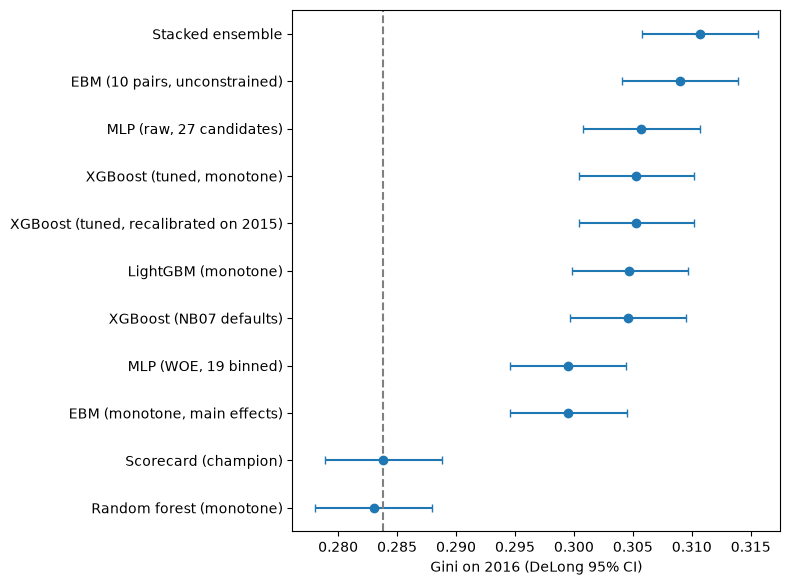

In [15]:
# Gini with DeLong 95% intervals on 2016
c = cmp.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.45 * len(c) + 1))
ax.errorbar(c.gini, range(len(c)), xerr=[c.gini - c.gini_ci_low, c.gini_ci_high - c.gini], fmt="o", capsize=3)
ax.axvline(cmp.set_index("model").loc["Scorecard (champion)", "gini"], ls="--", c="grey")
ax.set_yticks(range(len(c))); ax.set_yticklabels(c.model); ax.set_xlabel("Gini on 2016 (DeLong 95% CI)"); plt.tight_layout(); plt.show()